# Satellite altimetry (IMOS, 1985-present) from the cloud

Along-track significant wave height (Hs) and wind speed of **18 altimeter missions**
(GEOSAT 1985 to Sentinel-6A and the SWOT nadir altimeter), calibrated against buoys
(Ribal and Young, 2019; IMOS DM00 archive), served by GeoOcean as a Zarr store.

The store has one dimension `obs`, sorted by 1x1 degree cell and time, and a cell index
(`cell_start`, `cell_count`), so the observations around a point are read as a few small
slices. `bluemath_tk.waves.altimetry` does it for you.

Requirements: `bluemath-tk` (with `bluemath_tk.waves.altimetry`), `xarray`, `zarr>=3`, `fsspec`, `aiohttp`, `matplotlib`, `cartopy`. The stores are read over HTTP: only the chunks needed are downloaded.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from bluemath_tk.core.metrics import compute_metrics
from bluemath_tk.waves.altimetry import open_altimeter, altimeter_near, altimeter_passes, collocate

# Public GeoOcean Zarr stores. On the GeoOcean cluster use "http://geocean01.sci.unican.es/zarr" (faster).
BASE = "https://geoocean.unican.es/zarr"
IMOS_URL = f"{BASE}/IMOS/imos_altimeter_dm00.zarr"
SWOT_URL = f"{BASE}/SWOT/swot_karin_windwave.zarr"
WHACS_URL = f"{BASE}/CSIRO/whacs_global_smc_1h_2020_2023.zarr"

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"axes.grid": True, "grid.color": "#e4e3df", "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

LON, LAT = -3.8, 43.7  # Cantabrian Sea, ~20 km off Santander

## Open the store

Its attributes say what it is and how to use it.

In [2]:
ds = open_altimeter(IMOS_URL)
for key in ("title", "summary", "usage", "time_coverage_start", "time_coverage_end", "license"):
    print(f"{key}: {ds.attrs[key]}\n")
ds

title: IMOS altimeter wave height and wind speed, 18 missions, 1985-present

summary: Along-track significant wave height (hs), wind speed (wspd) and backscatter of 18 altimeter missions, GEOSAT (1985) to Sentinel-6A and the SWOT nadir altimeter, from the IMOS DM00 archive: calibrated against buoys (Ribal and Young 2019, updated) and raw values, IMOS quality flags, distance to the coast and depth (GEBCO 2026). ~1 Hz along track (CFOSAT 5 Hz). Rebuilt at each IMOS release.

usage: One dimension obs, sorted by 1x1 degree cell and then by time; cell_start and cell_count on (lat_cell = floor(latitude), lon_cell = floor(longitude), longitudes 0-360) give the slice of obs of each cell, e.g. ds.isel(obs=slice(start, start + count)). Keep flag 1-2 (IMOS flags: 1 good, 2 probably good, 3-4 bad). Mission names are in satellite.flag_meanings. Successive values are correlated and CFOSAT has 5 per second: reduce to one value per satellite pass before statistics.

time_coverage_start: 1985-03-31

ti

<xarray.Dataset> Size: 318GB
Dimensions:           (obs: 3343332707, lat_cell: 180, lon_cell: 360)
Coordinates:
    latitude          (obs) float32 13GB dask.array<chunksize=(32768,), meta=np.ndarray>
    longitude         (obs) float32 13GB dask.array<chunksize=(32768,), meta=np.ndarray>
    time              (obs) datetime64[ns] 27GB dask.array<chunksize=(32768,), meta=np.ndarray>
  * lat_cell          (lat_cell) int16 360B -90 -89 -88 -87 -86 ... 86 87 88 89
  * lon_cell          (lon_cell) int16 720B 0 1 2 3 4 5 ... 355 356 357 358 359
Dimensions without coordinates: obs
Data variables: (12/26)
    bot_depth         (obs) float32 13GB dask.array<chunksize=(32768,), meta=np.ndarray>
    cell_count        (lat_cell, lon_cell) int32 259kB 0 0 0 0 0 0 ... 0 0 0 0 0
    cell_start        (lat_cell, lon_cell) int64 518kB 0 0 ... 3343332707
    depth             (obs) int16 7GB dask.array<chunksize=(32768,), meta=np.ndarray>
    dist2coast        (obs) float32 13GB dask.array<chunksize=(32768,), meta=np.ndarray>
    flag              (obs) int8 3GB dask.array<chunksize=(32768,), meta=np.ndarray>
    ...                ...
    sig0_num_obs      (obs) float32 13GB dask.array<chunksize=(32768,), meta=np.ndarray>
    sig0_std          (obs) float32 13GB dask.array<chunksize=(32768,), meta=np.ndarray>
    uwnd              (obs) float32 13GB dask.array<chunksize=(32768,), meta=np.ndarray>
    vwnd              (obs) float32 13GB dask.array<chunksize=(32768,), meta=np.ndarray>
    wspd              (obs) float32 13GB dask.array<chunksize=(32768,), meta=np.ndarray>
    wspd_raw          (obs) float32 13GB dask.array<chunksize=(32768,), meta=np.ndarray>
Attributes: (12/14)
    title:                IMOS altimeter wave height and wind speed, 18 missi...
    summary:              Along-track significant wave height (hs), wind spee...
    usage:                One dimension obs, sorted by 1x1 degree cell and th...
    source:               IMOS multi-mission altimeter archive Wave-Wind-Alti...
    source_url:           https://imos.org.au
    references:           Ribal, A. and Young, I. R. (2019). 33 years of glob...
    ...                   ...
    creator_name:         GeoOcean, Universidad de Cantabria
    creator_url:          https://geoocean.unican.es
    time_coverage_start:  1985-03-31
    time_coverage_end:    2026-07-03
    date_modified:        2026-10-27T16:47:17Z
    Conventions:          CF-1.8

In [3]:
satellites = np.array(ds["satellite"].attrs["flag_meanings"].split())
print(ds["satellite"].attrs["comment"])
satellites

SWOT is its nadir altimeter (not KaRIn); HY-2A is the IMOS folder HY-2; SARAL measures in Ka band, all others in Ku; CFOSAT is sampled at 5 Hz, the others at ~1 Hz (reduce to one value per pass before statistics)


array(['GEOSAT', 'ERS-1', 'TOPEX', 'ERS-2', 'GFO', 'JASON-1', 'ENVISAT',
       'JASON-2', 'CRYOSAT-2', 'HY-2A', 'SARAL', 'JASON-3', 'SENTINEL-3A',
       'SENTINEL-3B', 'CFOSAT', 'HY-2B', 'SENTINEL-6A', 'SWOT'],
      dtype='<U11')

## Observations around a point

All observations within 50 km of the point, in water deeper than 20 m, with good or
probably good quality flags (the default `flags=(1, 2)`).

In [4]:
obs = altimeter_near(ds, LON, LAT, radius_km=50, min_depth=20)
print(f"{len(obs):,} observations, {obs.time.min():%Y-%m-%d} to {obs.time.max():%Y-%m-%d}")
obs.assign(satellite=satellites[obs.satellite]).head()

41,934 observations, 1985-04-11 to 2026-07-01


,hs,flag,depth,dist2coast,satellite,time,latitude,longitude,lon,distance_km
0,3.992,1,-2430.0,61.0,GEOSAT,1985-04-11 20:45:29.250,44.122131,356.186890,-3.813110,46.950539
1,4.088,1,-2487.0,59.0,GEOSAT,1985-04-11 20:45:30.234,44.069508,356.147949,-3.852051,41.298572
2,4.137,1,-2402.0,54.0,GEOSAT,1985-04-11 20:45:31.203,44.016872,356.109100,-3.890869,35.979768
3,3.809,1,-2273.0,48.0,GEOSAT,1985-04-11 20:45:32.187,43.964222,356.070312,-3.929688,31.167200
4,3.579,1,-2293.0,43.0,GEOSAT,1985-04-11 20:45:33.172,43.911564,356.031555,-3.968445,27.131748


One year of tracks: each line is a satellite crossing the 50 km circle.

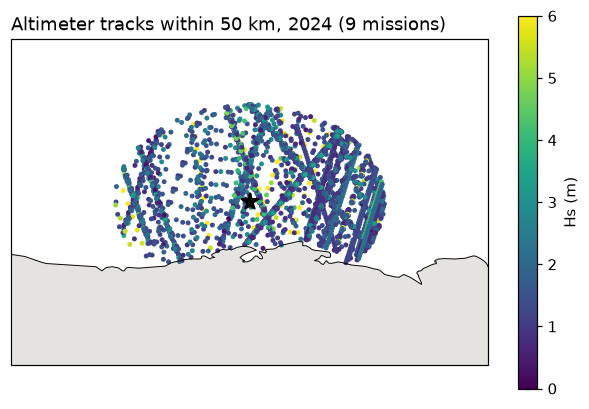

In [5]:
year = obs[obs.time.dt.year == 2024]
fig = plt.figure(figsize=(7, 5.5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([LON - 1.1, LON + 1.1, LAT - 0.75, LAT + 0.75])
ax.add_feature(cfeature.LAND.with_scale("10m"), color="#e4e3df", zorder=0)
ax.coastlines("10m", lw=0.6)
sc = ax.scatter(year.lon, year.latitude, c=year.hs, s=5, cmap="viridis", vmin=0, vmax=6,
                transform=ccrs.PlateCarree())
ax.plot(LON, LAT, "*", color="k", ms=12, transform=ccrs.PlateCarree())
plt.colorbar(sc, label="Hs (m)", shrink=0.8)
ax.set_title(f"Altimeter tracks within 50 km, 2024 ({year.satellite.nunique()} missions)", loc="left")
plt.show()

## One value per pass

Successive 1 Hz values along a track are strongly correlated (and CFOSAT has 5 per
second), so before any statistics each crossing of the circle is reduced to its median.

4,754 passes


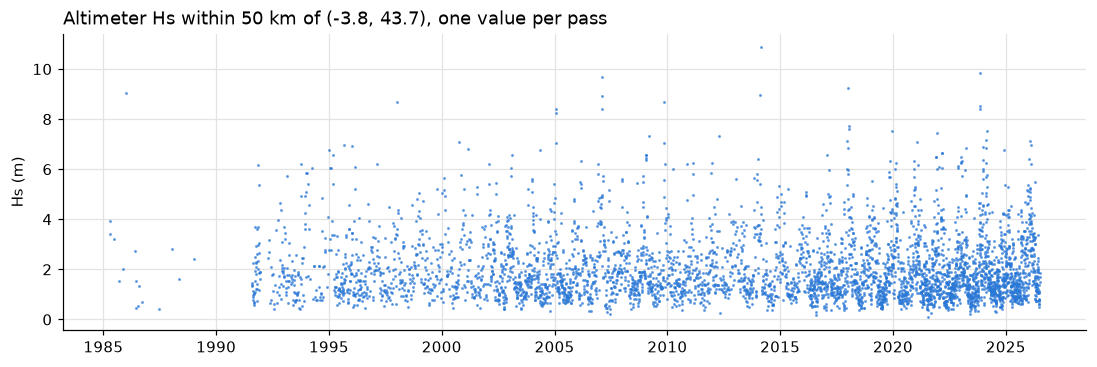

In [6]:
passes = altimeter_passes(obs)
passes["satellite"] = satellites[passes.satellite.astype(int)]
print(f"{len(passes):,} passes")

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(passes.index, passes.hs, ".", color=BLUE, ms=2, alpha=0.6)
ax.set_ylabel("Hs (m)")
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.set_title(f"Altimeter Hs within 50 km of ({LON}, {LAT}), one value per pass", loc="left")
plt.show()

## Statistics

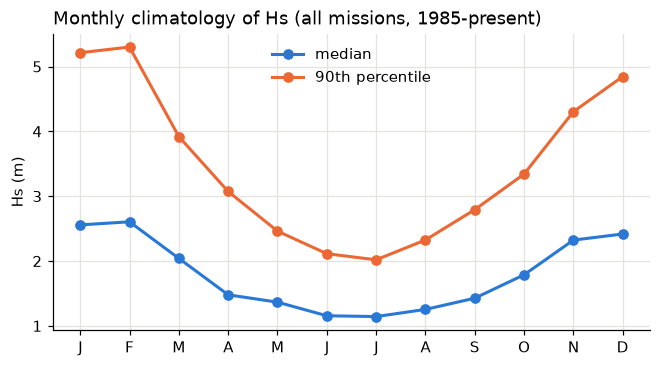

In [7]:
monthly = passes.groupby(passes.index.month).hs.agg(median="median", p90=lambda x: x.quantile(0.9))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(monthly.index, monthly["median"], "o-", color=BLUE, lw=2, label="median")
ax.plot(monthly.index, monthly["p90"], "o-", color=ORANGE, lw=2, label="90th percentile")
ax.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_ylabel("Hs (m)")
ax.set_title("Monthly climatology of Hs (all missions, 1985-present)", loc="left")
ax.legend(frameon=False)
plt.show()

Passes and Hs per mission, in launch order: the record is made of many missions.

In [8]:
per_mission = passes.groupby("satellite").agg(
    first=("hs", lambda x: x.index.min().year), last=("hs", lambda x: x.index.max().year),
    passes=("hs", "size"), hs_median=("hs", "median"), hs_p90=("hs", lambda x: x.quantile(0.9)))
per_mission.sort_values("first").round(2)

,first,last,passes,hs_median,hs_p90
satellite,,,,,
GEOSAT,1985,1989,16,1.82,3.67
ERS-1,1991,1996,161,1.56,3.58
TOPEX,1992,2005,400,1.78,4.01
ERS-2,1995,2009,526,1.76,3.70
JASON-1,2002,2013,383,1.72,3.72
ENVISAT,2002,2012,359,1.64,3.73
JASON-2,2008,2019,374,1.67,3.86
HY-2A,2011,2018,167,1.66,3.88
CRYOSAT-2,2012,2026,200,1.58,3.26


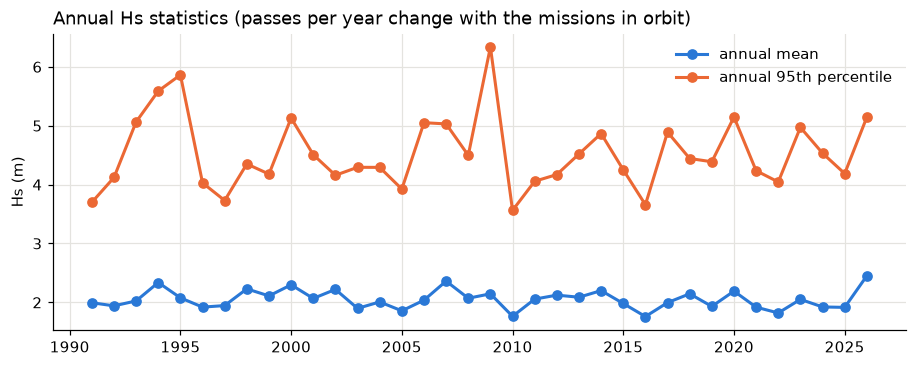

In [9]:
annual = passes.hs.resample("YS").agg(["mean", lambda x: x.quantile(0.95), "size"])
annual.columns = ["mean", "p95", "passes"]
annual = annual[annual.passes >= 20]  # years with too few passes are left out
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(annual.index.year, annual["mean"], "o-", color=BLUE, lw=2, label="annual mean")
ax.plot(annual.index.year, annual["p95"], "o-", color=ORANGE, lw=2, label="annual 95th percentile")
ax.set_ylabel("Hs (m)")
ax.set_title("Annual Hs statistics (passes per year change with the missions in orbit)", loc="left")
ax.legend(frameon=False)
plt.show()

## Notes

- Keep the quality flags (`flag` 1-2) and reduce to one value per pass before statistics.
- Sampling changes with time: 1-3 missions before 2000, up to 9 after 2020.
- Near the coast the altimeter footprint degrades: `min_depth` and `min_dist2coast` help.
- Cite Ribal and Young (2019) and acknowledge IMOS (see the store `license`).